## Лабораторная работа № 2
## Машинное обучение на больших данных (Apache Spark, SparkML)

### Часть 1. Линейная регрессия

Датасет — таблица `Apache Iceberg` с предобработанными событиями интернет-магазина, созданная в лабораторной работе № 1 (более 100 млн событий; цены очищены от выбросов).

**Постановка задачи:** построить модель **линейной регрессии** для предсказания **цены товара** (`price`) по остальным признакам события. Качество оцениваем метриками **RMSE** и **R²**.

Модель регрессии — `LinearRegression` (вариант по таблице задания).

#### Признаки для модели

Из таблицы лабораторной работы № 1 используем:

| Признак | Тип | Роль в модели |
| ---- | ---- | ---- |
| `price` | количественный | целевая переменная |
| `category_l1` | категориальный | признак (one-hot) |
| `brand` | категориальный | признак (one-hot, топ-20 брендов) |
| `hour`, `day_of_week` | количественные | признаки (масштабируются) |
| `user_activity`, `product_popularity` | количественные | признаки (масштабируются) |

Идентификаторы (`product_id`, `user_id`, `user_session`, `event_time`, `category_id`, `category_code`) в модель не включаем — по той же логике, по которой в примере с автомобилями исключен `vin`: идентификатор не обобщается на новые объекты, а `event_type` не связан с ценой товара (цена — свойство товара, а не события).

Подключим библиотеки.

In [1]:
# Модуль для работы с окружением (получение имени пользователя)
import os

# Классы PySpark: сессия и работа с данными
from pyspark.sql import SparkSession
# Объект конфигурации Spark-приложения
from pyspark import SparkConf

# Трансформеры подготовки признаков:
# VectorAssembler - сборка нескольких столбцов в один вектор;
# StringIndexer - категория -> номер (label encoding);
# OneHotEncoder - номер категории -> one-hot вектор;
# MinMaxScaler - масштабирование числовых признаков в диапазон [0, 1]
from pyspark.ml.feature import VectorAssembler, StringIndexer, OneHotEncoder, MinMaxScaler
# Модель линейной регрессии
from pyspark.ml.regression import LinearRegression
# Оценщик качества регрессии
from pyspark.ml.evaluation import RegressionEvaluator
# Кросс-валидация и построитель сетки гиперпараметров
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder
# Конвейер обработки данных (pipeline)
from pyspark.ml import Pipeline

# Функции над столбцами: col - ссылка на столбец; when - условие;
# lit - константа; desc - сортировка по убыванию
from pyspark.sql.functions import col, when, lit, desc

# Pandas, Seaborn, Matplotlib - таблицы и графики на драйвере
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

#### Запуск Spark-сессии

In [2]:
# Имя пользователя из переменной окружения (каталог в HDFS)
user_name = os.getenv("USER")

# Создаем пустой объект конфигурации
# Подключаем библиотеку Iceberg на уровне spark-submit:
# пакеты из spark.jars.packages разрешаются только при запуске JVM,
# поэтому задаем их через переменную окружения ДО создания сессии
os.environ["PYSPARK_SUBMIT_ARGS"] = (
    "--packages org.apache.iceberg:iceberg-spark-runtime-3.5_2.12:1.6.0 pyspark-shell"
)

conf = SparkConf()
# Имя приложения - видно в веб-интерфейсе YARN
conf.setAppName("lab2 LR korolev")
# Запуск на кластере через менеджер ресурсов YARN
conf.setMaster("yarn")
# Режим client: драйвер работает в нашей сессии VS Code
conf.set("spark.submit.deployMode", "client")
# Память одного исполнителя
conf.set("spark.executor.memory", "12g")
# Число ядер одного исполнителя
conf.set("spark.executor.cores", "8")
# Число исполнителей
conf.set("spark.executor.instances", "2")
# Память драйвера
conf.set("spark.driver.memory", "4g")
# Число ядер драйвера
conf.set("spark.driver.cores", "2")
# Библиотека Apache Iceberg
conf.set("spark.jars.packages", "org.apache.iceberg:iceberg-spark-runtime-3.5_2.12:1.6.0")
# Расширения Spark SQL с командами Iceberg
conf.set("spark.sql.extensions", "org.apache.iceberg.spark.extensions.IcebergSparkSessionExtensions")
# Каталог spark_catalog обслуживается Iceberg
conf.set("spark.sql.catalog.spark_catalog", "org.apache.iceberg.spark.SparkCatalog")
# Тип каталога - hadoop
conf.set("spark.sql.catalog.spark_catalog.type", "hadoop")
# Путь к складу таблиц Iceberg в HDFS
conf.set("spark.sql.catalog.spark_catalog.warehouse", f"hdfs:///user/{user_name}/warehouse")
# Реализация файлового ввода-вывода
conf.set("spark.sql.catalog.spark_catalog.io-impl", "org.apache.iceberg.hadoop.HadoopFileIO")

In [3]:
# Создаем Spark-сессию с заданной конфигурацией
spark = SparkSession.builder.config(conf=conf).getOrCreate()
spark

:: loading settings :: url = jar:file:/opt/spark-3.5.2-bin-hadoop3/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /home/user5/.ivy2/cache
The jars for the packages stored in: /home/user5/.ivy2/jars
org.apache.iceberg#iceberg-spark-runtime-3.5_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-4e44836d-477a-46be-95f9-c6dee3ce2131;1.0
	confs: [default]
	found org.apache.iceberg#iceberg-spark-runtime-3.5_2.12;1.6.0 in central
:: resolution report :: resolve 588ms :: artifacts dl 23ms
	:: modules in use:
	org.apache.iceberg#iceberg-spark-runtime-3.5_2.12;1.6.0 from central in [default]
	---------------------------------------------------------------------
	|                  |            modules            ||   artifacts   |
	|       conf       | number| search|dwnlded|evicted|| number|dwnlded|
	---------------------------------------------------------------------
	|      default     |   1   |   0   |   0   |   0   ||   1   |   0   |
	---------------------------------------------------------------------
:: retrieving :: org.apache.spa

#### Загрузка данных

Читаем таблицу с предобработанными данными из `Apache Iceberg` (создана в лабораторной работе № 1).

In [4]:
# Имена базы данных и таблицы из лабораторной работы №1 (фамилия студента)
database_name = "korolev_database"
table_name = "korolev_lab1_events_processed"

# Делаем базу данных текущей (она создана в лабораторной работе №1)
spark.catalog.setCurrentDatabase(database_name)

# Читаем таблицу в датафрейм
df = spark.table(table_name)

# Смотрим первые строки
df.show(5, truncate=False)

+----------+---------+-------------------+----------+-------------------+----------------------+-----+------+------------------------------------+----------+----+-----------+-----------+-------------+------------------+
|product_id|user_id  |event_time         |event_type|category_id        |category_code         |brand|price |user_session                        |event_date|hour|day_of_week|category_l1|user_activity|product_popularity|
+----------+---------+-------------------+----------+-------------------+----------------------+-----+------+------------------------------------+----------+----+-----------+-----------+-------------+------------------+
|1003305   |512383119|2019-10-15 04:42:07|view      |2053013555631882655|electronics.smartphone|apple|598.27|86137e31-0d5b-4099-ac2c-2139abc2cf00|2019-10-15|4   |3          |electronics|25           |23439             |
|1003305   |512451892|2019-11-03 10:03:42|view      |2053013555631882655|electronics.smartphone|apple|596.75|364f8a15-be

In [5]:
# Оставляем только столбцы, которые будут использованы в модели
# (идентификаторы и event_time исключены - см. пояснение выше)
df = df.select("price", "category_l1", "brand", "hour", "day_of_week",
               "user_activity", "product_popularity")

#### Сокращение выборки

Полная таблица содержит более 100 млн строк. Перебор гиперпараметров на кросс-валидации потребовал бы десятков обучений модели, поэтому для ускорения возьмем **случайную 5%-ю выборку** — в ней все равно несколько миллионов строк, чего для линейной регрессии более чем достаточно (стандартная практика на больших данных).

In [6]:
# Случайная 5%-я выборка без возвращения (seed фиксируем для воспроизводимости)
df = df.sample(withReplacement=False, fraction=0.05, seed=42)

# Кэшируем выборку в памяти - она будет использоваться многократно
df = df.cache()

# Число строк в выборке
df.count()

5420429

#### Ограничение числа брендов

Признак `brand` содержит тысячи уникальных значений. One-hot кодирование по всем брендам создало бы тысячи столбцов. Ограничим признак **топ-20 брендов** по числу событий, остальные объединим в категорию `other`.

In [7]:
# Считаем события по брендам, сортируем по убыванию и берем топ-20;
# collect() выгружает маленькую таблицу (20 строк) на драйвер списком
top_brands = [row["brand"] for row in
              df.groupBy("brand").count().orderBy(desc("count")).limit(20).collect()]

# Новый столбец brand_top: бренд из топ-20 остается, прочие заменяются на "other"
df = df.withColumn("brand_top",
                   when(col("brand").isin(top_brands), col("brand")).otherwise(lit("other")))

# Исходный столбец brand больше не нужен
df = df.drop("brand")

# Распределение итогового категориального признака
df.groupBy("brand_top").count().orderBy(desc("count")).show()

+---------+-------+
|brand_top|  count|
+---------+-------+
|    other|2194296|
|  unknown| 744934|
|  samsung| 652825|
|    apple| 498227|
|   xiaomi| 384500|
|   huawei| 126840|
|  lucente|  91669|
|       lg|  80832|
|    bosch|  76379|
|     oppo|  64020|
|     sony|  61154|
|     acer|  54069|
|   lenovo|  52385|
| cordiant|  51962|
|  respect|  51604|
|    artel|  49683|
|       hp|  40317|
|  redmond|  37083|
|  philips|  36611|
|  indesit|  35886|
+---------+-------+
only showing top 20 rows



#### Выборка для следующей лабораторной работы

Отделим небольшую часть данных (~1000 строк) и сохраним ее в локальный `csv`-файл — он понадобится в лабораторной работе по потоковой обработке.

In [8]:
# Случайный маленький кусочек данных и ограничение 1000 строк
sample_1000 = df.sample(withReplacement=False, fraction=0.001, seed=42).limit(1000)

# Выгружаем 1000 строк в pandas (это мало - влезает в память драйвера)
# и записываем csv-файл (index=False - не писать номера строк pandas)
sample_1000.toPandas().to_csv("streaming-data.csv", index=False)

#### Разделение на обучающую и тестовую выборки

In [9]:
# Делим данные: 80% - обучение, 20% - тест (seed - для воспроизводимости)
train_df, test_df = df.randomSplit([0.8, 0.2], seed=42)

# Кэшируем обе выборки - они используются неоднократно
train_df = train_df.cache()
test_df = test_df.cache()

# Размеры выборок
print(f"Train: {train_df.count()}")
print(f"Test: {test_df.count()}")

Train: 4334583


Test: 1085846


#### Конвейер подготовки признаков и модели

Соберем конвейер (`Pipeline`) из шагов:

1. **Категориальные** признаки (`category_l1`, `brand_top`): `StringIndexer` (категория → номер) → `OneHotEncoder` (номер → вектор из 0/1);
2. **Числовые** признаки (`hour`, `day_of_week`, `user_activity`, `product_popularity`): сборка в вектор → `MinMaxScaler` (масштабирование в [0, 1] — важно для линейной модели, чтобы признаки с большими значениями не «перетягивали» веса);
3. Итоговая сборка всех признаков в столбец `features`;
4. `LinearRegression` — предсказываем `price`.

Бинарных признаков, как в примере с автомобилями, в нашем датасете нет.

In [10]:
# Списки признаков по типам
categorical_features = ["category_l1", "brand_top"]
numeric_features = ["hour", "day_of_week", "user_activity", "product_popularity"]

# Шаг 1: категория -> номер категории (handleInvalid="keep" - незнакомая категория не уронит модель)
indexer = StringIndexer(inputCols=categorical_features,
                        outputCols=["category_l1_index", "brand_top_index"],
                        handleInvalid="keep")

# Шаг 2: номер категории -> one-hot вектор
encoder = OneHotEncoder(inputCols=["category_l1_index", "brand_top_index"],
                        outputCols=["category_l1_ohe", "brand_top_ohe"])

# Шаг 3а: числовые признаки собираем в один вектор
num_assembler = VectorAssembler(inputCols=numeric_features, outputCol="numeric_vector")

# Шаг 3б: масштабируем числовые в диапазон [0, 1]
scaler = MinMaxScaler(inputCol="numeric_vector", outputCol="numeric_vector_scaled")

# Шаг 4: все признаки вместе -> итоговый вектор features
assembler = VectorAssembler(inputCols=["category_l1_ohe", "brand_top_ohe", "numeric_vector_scaled"],
                            outputCol="features")

# Шаг 5: модель линейной регрессии (maxIter - число итераций градиентного спуска)
lr = LinearRegression(featuresCol="features", labelCol="price", maxIter=15)

# Собираем все шаги в конвейер
pipeline = Pipeline(stages=[indexer, encoder, num_assembler, scaler, assembler, lr])

#### Обучение с подбором гиперпараметров

Подберем кросс-валидацией (5 фолдов) гиперпараметры регуляризации:

* `regParam` — сила регуляризации (штраф на большие веса — защита от переобучения);
* `elasticNetParam` — смесь L1/L2-регуляризации: 0 — только L2 (Ridge), 1 — только L1 (Lasso), 0.5 — смесь.

In [11]:
# Сетка гиперпараметров: 3 x 3 = 9 комбинаций
param_grid = (ParamGridBuilder()
              .addGrid(lr.regParam, [0.01, 0.1, 1.0])        # сила регуляризации
              .addGrid(lr.elasticNetParam, [0.0, 0.5, 1.0])  # смесь L1/L2
              .build())

# Оценщик качества: RMSE предсказания цены (чем меньше - тем лучше)
evaluator = RegressionEvaluator(labelCol="price", predictionCol="prediction",
                                metricName="rmse")

# Кросс-валидация: 5 фолдов, лучшая модель выбирается по RMSE
cross_validator = CrossValidator(estimator=pipeline,
                                 estimatorParamMaps=param_grid,
                                 evaluator=evaluator,
                                 numFolds=5)

# Обучение: 9 комбинаций x 5 фолдов = 45 обучений (операция долгая)
cv_model = cross_validator.fit(train_df)

26/11/05 19:06:54 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.JNIBLAS
26/11/05 19:06:55 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.lapack.JNILAPACK


In [12]:
# Лучшая модель конвейера, найденная кросс-валидацией
best_model = cv_model.bestModel

# Гиперпараметры модели линейной регрессии (последний этап конвейера)
print(f"regParam: {best_model.stages[-1].getRegParam()}")
print(f"elasticNetParam: {best_model.stages[-1].getElasticNetParam()}")
print(f"maxIter: {best_model.stages[-1].getMaxIter()}")

regParam: 0.01
elasticNetParam: 0.0
maxIter: 15


#### Анализ процесса обучения

Построим график значения функции ошибки по итерациям и посмотрим метрики на обучающей выборке.

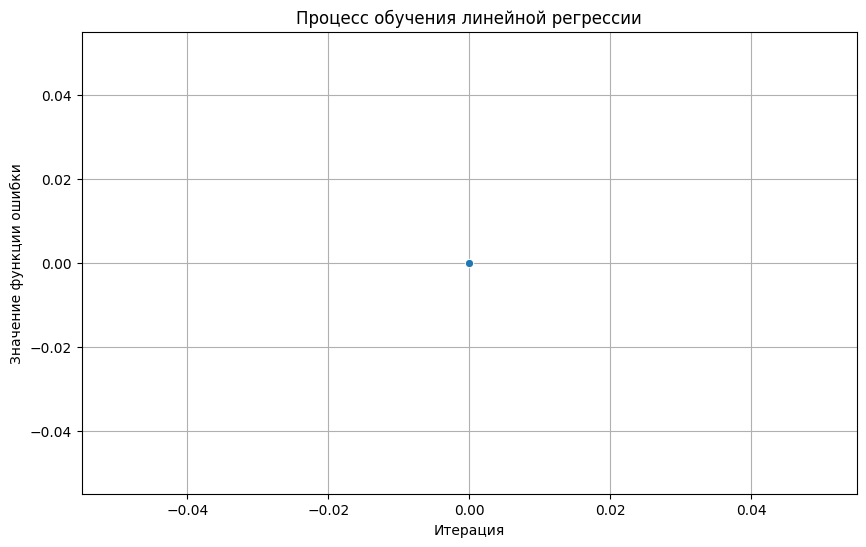

RMSE (train): 240.00
R^2 (train): 0.387


In [13]:
# Сводка обучения модели линейной регрессии
training_summary = best_model.stages[-1].summary

# Значения функции ошибки на каждой итерации
objective_history = training_summary.objectiveHistory

plt.figure(figsize=(10, 6))
# Линия с маркерами: ошибка от номера итерации
sns.lineplot(x=range(len(objective_history)), y=objective_history, marker="o")
plt.xlabel("Итерация")
plt.ylabel("Значение функции ошибки")
plt.title("Процесс обучения линейной регрессии")
plt.grid(True)
plt.show()

# Метрики на обучающей выборке
print(f"RMSE (train): {training_summary.rootMeanSquaredError:.2f}")
print(f"R^2 (train): {training_summary.r2:.3f}")

#### Проверка на тестовой выборке

In [14]:
# Применяем конвейер с лучшей моделью к тестовой выборке
test_predictions = cv_model.transform(test_df)

# Предсказанная и фактическая цена рядом
test_predictions.select("prediction", "price").show(10)

+------------------+-----+
|        prediction|price|
+------------------+-----+
|320.97807433334236| 1.42|
| 153.6930610926769| 2.29|
| 394.0964287506982| 2.32|
|146.41556732105707| 2.51|
|149.80992860034212| 2.51|
|151.91368623719228| 2.51|
|147.47357436020263| 2.57|
| 176.4852323393876| 2.88|
| 177.6915936635862| 3.24|
|179.17588994723445| 3.24|
+------------------+-----+
only showing top 10 rows



In [15]:
# RMSE на тесте (средняя ошибка предсказания в денежных единицах)
test_rmse = RegressionEvaluator(labelCol="price", predictionCol="prediction",
                                metricName="rmse").evaluate(test_predictions)

# R^2 на тесте (доля объясненной дисперсии целевой переменной, 1 - идеально)
test_r2 = RegressionEvaluator(labelCol="price", predictionCol="prediction",
                              metricName="r2").evaluate(test_predictions)

print(f"RMSE on test: {test_rmse:.2f}")
print(f"R^2 on test: {test_r2:.3f}")

RMSE on test: 240.31
R^2 on test: 0.387


**Анализ метрик.** RMSE показывает среднюю ошибку предсказания цены в денежных единицах; R² — какая доля дисперсии цены объясняется моделью. Для событийных данных электронной коммерции качество умеренное и ожидаемое: цена товара определяется в первую очередь конкретной моделью и характеристиками товара, которых в данных нет, — модель «видит» только категорию, бренд и контекст события. Значения RMSE на обучении и тесте близки друг к другу — переобучения нет.

#### Сохранение модели в HDFS

Сохраним обученную модель — она понадобится в следующей лабораторной работе.

In [16]:
# Путь модели в HDFS (в каталоге пользователя на кластере)
model_path = f"hdfs:///user/{user_name}/korolev/models/lab2-lr-model"

# Сохраняем лучшую модель конвейера
best_model.save(model_path)
print(f"Модель сохранена: {model_path}")

Модель сохранена: hdfs:///user/user5/korolev/models/lab2-lr-model


#### Выводы

* поставлена задача регрессии: предсказание цены товара по признакам события; идентификаторы исключены как неинформативные (аналог `vin` в примере);
* категориальные признаки закодированы one-hot (бренды ограничены топ-20), числовые масштабированы `MinMaxScaler`-ом; все шаги собраны в воспроизводимый конвейер `Pipeline`;
* гиперпараметры `regParam` и `elasticNetParam` подобраны кросс-валидацией по 5 фолдам;
* качество на тесте: значения RMSE и R² см. в ячейках выше — R² умеренный, что типично для событийных данных без характеристик конкретных товаров; метрики train/test близки — переобучения нет;
* часть данных сохранена в `streaming-data.csv`, модель сохранена в HDFS для следующих работ.

In [17]:
# Останавливаем Spark-сессию
spark.stop()